# 02 · Feature engineering and model development

Production training is `python -m src.train` (tracked in MLflow). This notebook documents the
**reasoning**: baseline comparison, the tuning grids, and the final results.

In [1]:
import sys, warnings
from pathlib import Path

here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / "src" / "config.py").exists()), here)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import json
import pandas as pd
from IPython.display import Image, display

from src import config
pd.set_option("display.max_columns", 30)

## 1. Feature engineering

* **Continuous** (`age, trestbps, chol, thalach, oldpeak`): median imputation + `StandardScaler`.
* **Categorical** (`sex, cp, fbs, restecg, exang, slope, ca, thal`): most-frequent imputation + one-hot (`handle_unknown="ignore"` so unseen codes cannot crash serving).
* Everything lives in one `ColumnTransformer` inside the model `Pipeline`, so training and inference are identical.

In [2]:
from src.data_processing import prepare_dataset, split_xy, build_preprocessor
from sklearn.pipeline import Pipeline

df = prepare_dataset()
X, y = split_xy(df)
pre = build_preprocessor().fit(X)
print("input features:", X.shape[1], "-> model features:", len(pre.get_feature_names_out()))
list(pre.get_feature_names_out())

input features: 13 -> model features: 28


['age',
 'trestbps',
 'chol',
 'thalach',
 'oldpeak',
 'sex_0.0',
 'sex_1.0',
 'cp_1.0',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'fbs_0.0',
 'fbs_1.0',
 'restecg_0.0',
 'restecg_1.0',
 'restecg_2.0',
 'exang_0.0',
 'exang_1.0',
 'slope_1.0',
 'slope_2.0',
 'slope_3.0',
 'ca_0.0',
 'ca_1.0',
 'ca_2.0',
 'ca_3.0',
 'thal_3.0',
 'thal_6.0',
 'thal_7.0']

## 2. Baseline comparison (default hyper-parameters, 5-fold stratified CV)

A quick sanity check before tuning: which model families look promising on this data?

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from src.train import model_specs, SCORING

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
rows = []
for name, (estimator, _) in model_specs(config.RANDOM_STATE).items():
    pipe = Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])
    scores = cross_validate(pipe, X, y, cv=cv, scoring=SCORING)
    rows.append({"model": name, **{m: scores[f"test_{m}"].mean() for m in SCORING}})
pd.DataFrame(rows).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
logistic_regression,0.855,0.874,0.798,0.833,0.919
random_forest,0.835,0.838,0.798,0.816,0.914
gradient_boosting,0.799,0.797,0.762,0.777,0.882


## 3. Tuning

`GridSearchCV` over the grids below, 5-fold stratified CV, refit on **ROC-AUC** (threshold-free
and robust to mild imbalance). The winner is chosen on CV ROC-AUC only; the 20 % hold-out set is
used once for the final, unbiased estimate.

In [4]:
for name, (_, grid) in model_specs(config.RANDOM_STATE).items():
    print(name)
    for param, values in grid.items():
        print("   ", param.removeprefix("model__"), "->", values)

logistic_regression
    C -> [0.01, 0.1, 1.0, 10.0]
    class_weight -> [None, 'balanced']
random_forest
    n_estimators -> [100, 300]
    max_depth -> [None, 4, 8]
    min_samples_leaf -> [1, 3, 5]
gradient_boosting
    n_estimators -> [100, 200]
    learning_rate -> [0.05, 0.1]
    max_depth -> [2, 3]


## 4. Results from the tracked training run

Run `python -m src.train` first. The numbers below are read from `models/metrics.json`.

In [5]:
metrics_path = config.METRICS_FILE
if metrics_path.exists():
    summary = json.loads(metrics_path.read_text())
    print("Selected model:", summary["best_model"], "| params:", summary["best_params"])
    display(pd.DataFrame(summary["all_models"]).T)
    display(pd.DataFrame({"CV (mean)": summary["cv"], "CV (std)": summary["cv_std"]}).T.round(3))
    display(pd.Series(summary["test"], name="hold-out test").to_frame().T)
else:
    print("No models/metrics.json yet: run `python -m src.train`")

Selected model: logistic_regression | params: {'C': 0.1, 'class_weight': 'balanced'}


,cv_roc_auc,test_roc_auc,test_accuracy,test_recall
logistic_regression,0.9028,0.9654,0.8852,0.9286
random_forest,0.9023,0.9481,0.8525,0.8929
gradient_boosting,0.8744,0.9610,0.9016,0.9286


,accuracy,precision,recall,f1,roc_auc
CV (mean),0.830,0.823,0.810,0.813,0.903
CV (std),0.017,0.044,0.068,0.023,0.017


,accuracy,precision,recall,f1,roc_auc
hold-out test,0.8852,0.8387,0.9286,0.8814,0.9654


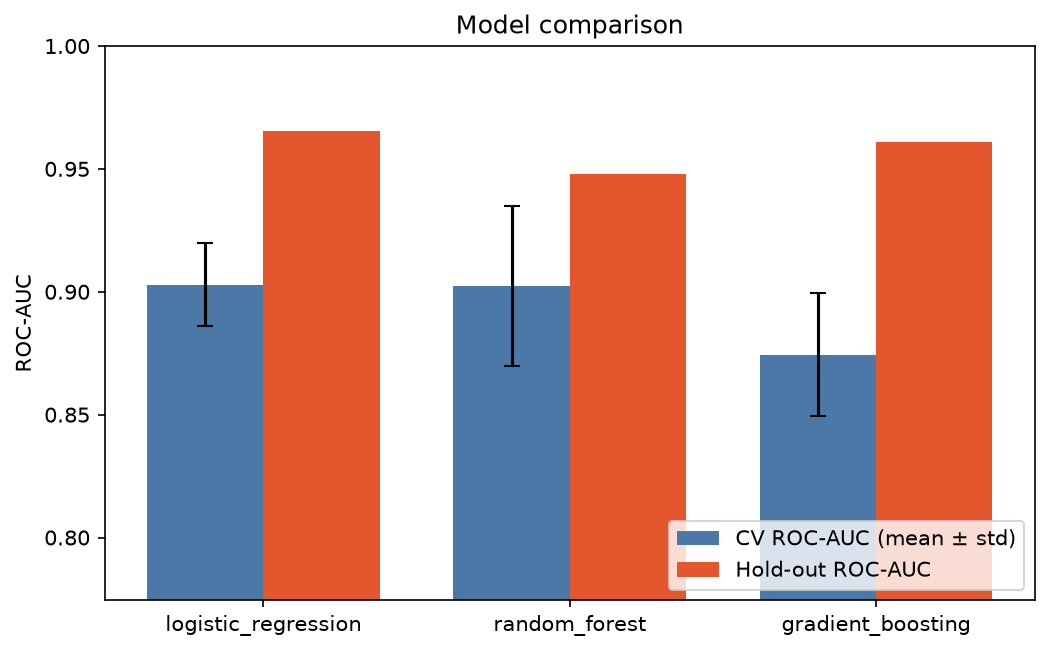

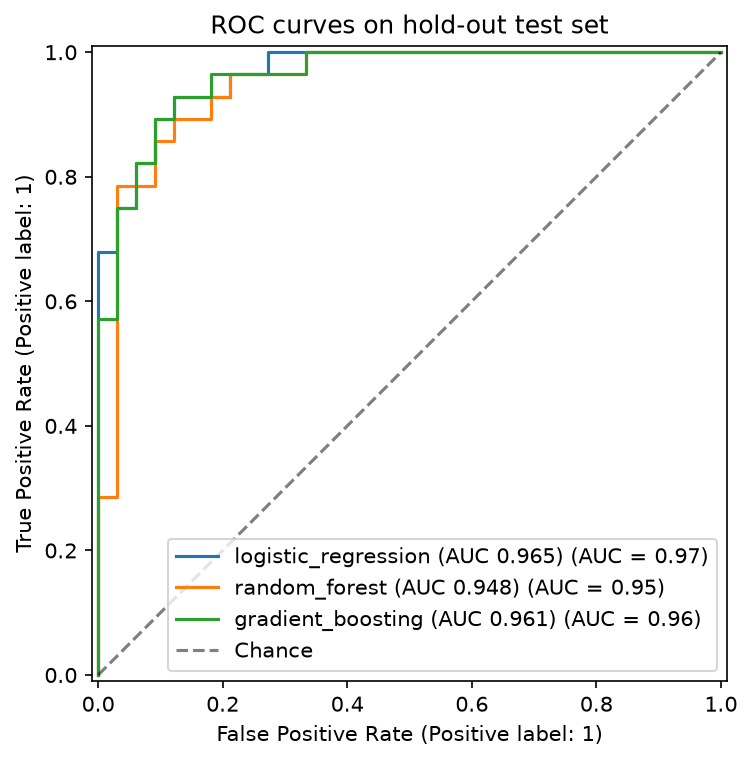

In [6]:
train_figs = config.FIGURES_DIR / "training"
for name in ["model_comparison.png", "roc_overlay.png"]:
    if (train_figs / name).exists():
        display(Image(filename=str(train_figs / name)))

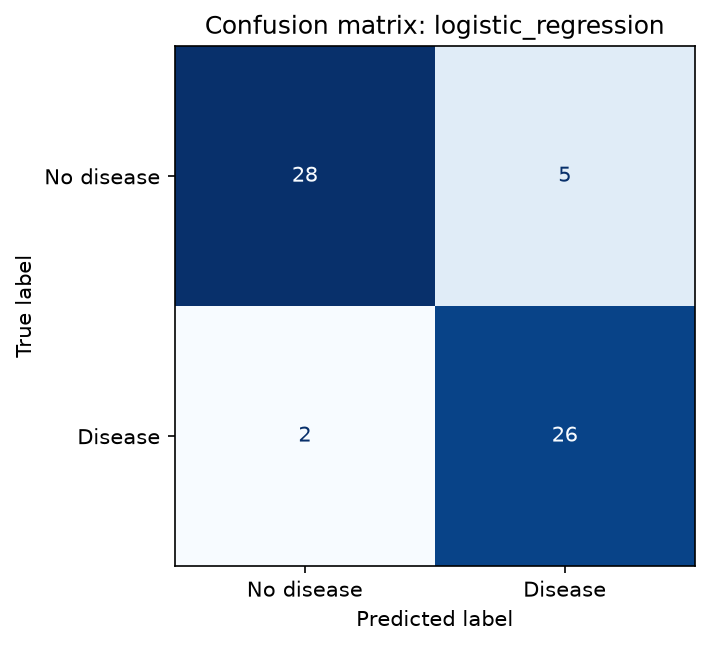

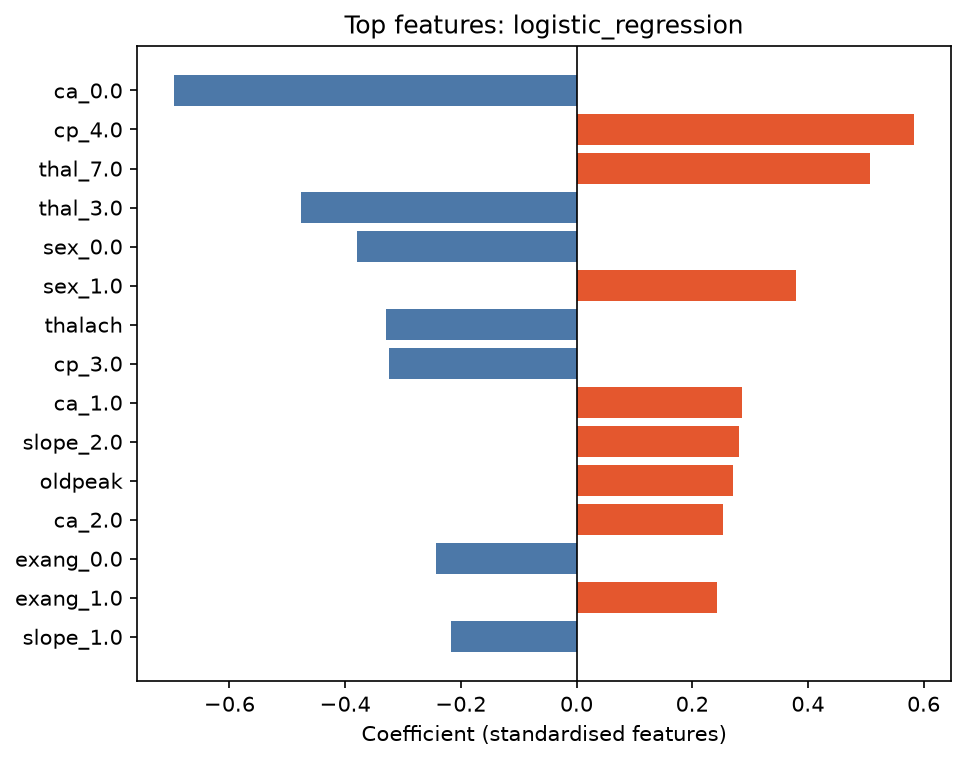

In [7]:
if metrics_path.exists():
    best = summary["best_model"]
    for name in [f"confusion_{best}.png", f"importance_{best}.png"]:
        if (train_figs / name).exists():
            display(Image(filename=str(train_figs / name)))

## 5. Interpretation checklist (write your own conclusions here)

* Which model won, and is the gap to the others larger than the CV standard deviation?
* Does the hold-out ROC-AUC agree with CV? A large gap would signal overfitting or an unlucky split.
* Recall on the disease class: how many sick patients are missed? Would you lower the decision threshold in a clinical setting?
* Which features dominate the importance plot, and does that match the EDA?